# Unsupervised metacell profiles from the transcriptogram

Using **only** the metacell transcriptogram (no cell-state labels), can we

1. find **positions / systems of higher variability**,
2. **cluster** metacells into data-driven *profiles*, and
3. **characterize / classify** those profiles?

The transcriptogram is a self-sufficient feature matrix (metacells × ordered positions), so this is a
standard unsupervised pipeline — with the twist that features are *interpretable systems*.

In [1]:
%matplotlib inline
import warnings
from pathlib import Path
import anndata as ad, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import adjusted_rand_score
import sctranscriptogramer as sctg

warnings.simplefilter("ignore"); sc.settings.verbosity = 0
OBJ = Path("/dora_zfs/home/deso14_OSUMC/projects/sctranscriptogram/testing/objects")
RES = Path("/dora_zfs/home/deso14_OSUMC/projects/sctranscriptogram/testing/results")

tg = ad.read_h5ad(OBJ / "tg_analysis.h5ad")
present = np.asarray(tg.uns["sctg"]["present_mask"], bool)
pos = tg.var["position"].to_numpy()
emb = np.asarray(tg.layers["transcriptogram"])
sym = tg.var["symbol"].to_numpy() if "symbol" in tg.var else tg.var["protein"].to_numpy()
radius = int(tg.uns["sctg"]["radius"])
print("transcriptogram:", emb.shape, "| present:", int(present.sum()))

transcriptogram: (68, 12396) | present: 11618


## 1. Highly variable systems (label-free)

Per-position variance across metacells is confounded by the mean (on log2CPM, low-abundance positions
are noisier). `sctg.tl.highly_variable_systems` fits a **mean–variance trend** across positions and
takes the **biological (residual) variance** — the transcriptogram analog of scran/Seurat HVG
selection. It writes a scanpy-style `highly_variable` flag to `tg.var` (so `sc.pp.pca(...,
use_highly_variable=True)` works) and groups the flagged positions into **regions** in `tg.uns`.

highly variable positions: 1162  ->  7 regions


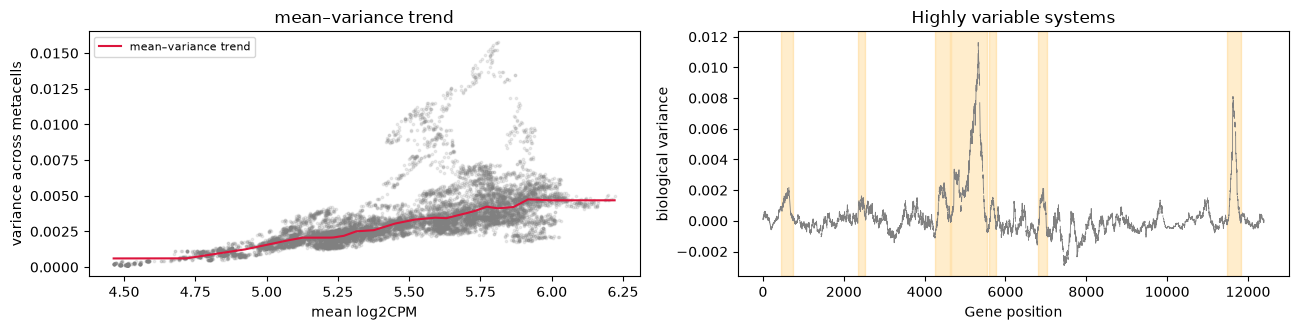

In [2]:
sctg.tl.highly_variable_systems(tg, quantile=0.90)
hv_info = tg.uns["highly_variable_systems"]
print(f"highly variable positions: {hv_info['n_highly_variable']}  ->  {hv_info['n_regions']} regions")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
mean_ = tg.var["hvs_mean"].to_numpy(); var_ = tg.var["hvs_variance"].to_numpy()
trend = tg.var["hvs_trend"].to_numpy(); bio = tg.var["hvs_biological_variance"].to_numpy()
o = np.argsort(mean_[present])
axes[0].scatter(mean_[present], var_[present], s=3, alpha=0.15, color="0.5")
axes[0].plot(mean_[present][o], trend[present][o], color="crimson", lw=1.5, label="mean–variance trend")
axes[0].set_xlabel("mean log2CPM"); axes[0].set_ylabel("variance across metacells")
axes[0].set_title("mean–variance trend"); axes[0].legend(fontsize=8)

axes[1].plot(pos, np.where(present, bio, np.nan), color="0.5", lw=0.6)
for lo, hi in hv_info["regions"]:
    axes[1].axvspan(lo, hi, color="orange", alpha=0.2)
axes[1].set_xlabel("Gene position"); axes[1].set_ylabel("biological variance")
axes[1].set_title("Highly variable systems")
plt.tight_layout(); plt.show()

hv = tg.var["highly_variable"].to_numpy()
hv_regions = type("R", (), {"intervals": hv_info["regions"], "n_clusters": hv_info["n_regions"]})

## 2. Cluster metacells into profiles

The transcriptogram is already an AnnData (metacells × positions), so clustering is standard scanpy —
run on the **highly variable systems** as features (scale → PCA → neighbors → Leiden). The resulting
`profile` labels are discovered **without** using any annotation.

discovered profiles: {'1': 13, '5': 12, '3': 11, '2': 10, '0': 9, '6': 9, '4': 4}


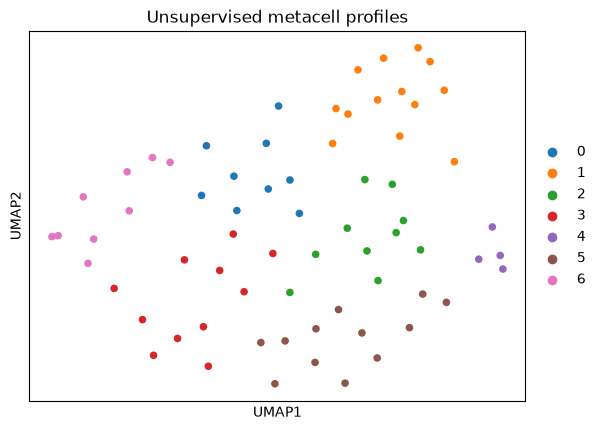

In [3]:
sub = tg[:, np.flatnonzero(hv)].copy()          # metacells x HV positions
sc.pp.scale(sub, max_value=10)
sc.pp.pca(sub, n_comps=min(30, sub.n_obs - 1))
sc.pp.neighbors(sub, n_neighbors=15)
sc.tl.leiden(sub, flavor="igraph", n_iterations=2, resolution=1.0, random_state=0)
sc.tl.umap(sub)
tg.obs["profile"] = sub.obs["leiden"].to_numpy()
tg.obsm["X_umap"] = sub.obsm["X_umap"]
print("discovered profiles:", tg.obs["profile"].value_counts().to_dict())

sc.pl.umap(sub, color="leiden", title="Unsupervised metacell profiles", size=120)

## 3. Characterize the profiles

Each profile is a *system-level signature*: the mean transcriptogram of a profile over the highly
variable regions. The heatmap (z-scored across profiles) shows which systems separate them; the table
lists the region where each profile is most extreme and its genes.

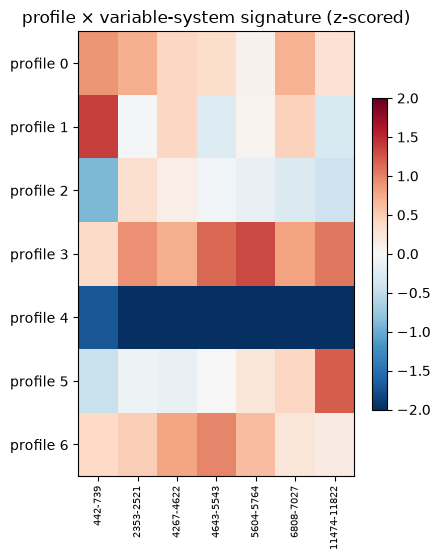

,region,profile_spread,genes
3,4643-5543,0.264,"OIP5, MIS18BP1, DHX32, TFAP2E, TFAP2D, CITED4,..."
2,4267-4622,0.250,"POLR1E, DDX21, MDM2, MDM4, FOSL1, EGR1, SMARCB..."
1,2353-2521,0.237,"LRRC41, FBXL22, WSB1, FBXO40, FBXO44, FBXO9, F..."
5,6808-7027,0.218,"LILRB1, LILRB5, LILRB4, GLG1, MGAT2, SELE, CLS..."
6,11474-11822,0.189,"NLRP7, NLRP12, ISCA1, HSCB, TIMM44, PAM16, PMP..."
4,5604-5764,0.171,"MRPL27, MRPL19, MRPL32, MRPL15, MRPL11, MRPL13..."
0,442-739,0.133,"ZIM3, ZNF514, ZNF25, ZNF597, ZNF331, ZNF615, Z..."


In [4]:
profiles = sorted(tg.obs["profile"].unique(), key=int)
region_ids = [f"{lo}-{hi}" for lo, hi in hv_regions.intervals]
M = np.zeros((len(profiles), len(hv_regions.intervals)))
for pi, p in enumerate(profiles):
    pm = tg.obs["profile"].to_numpy() == p
    for ri, (lo, hi) in enumerate(hv_regions.intervals):
        cols = np.arange(lo, hi + 1)[present[lo:hi + 1]]
        M[pi, ri] = emb[np.ix_(pm, cols)].mean() if cols.size else np.nan
Mz = (M - np.nanmean(M, 0)) / (np.nanstd(M, 0) + 1e-9)

fig, ax = plt.subplots(figsize=(min(1 + 0.5 * len(region_ids), 13), 0.6 * len(profiles) + 1.5))
im = ax.imshow(Mz, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(region_ids))); ax.set_xticklabels(region_ids, rotation=90, fontsize=7)
ax.set_yticks(range(len(profiles))); ax.set_yticklabels([f"profile {p}" for p in profiles])
ax.set_title("profile × variable-system signature (z-scored)")
fig.colorbar(im, ax=ax, shrink=0.7); plt.tight_layout(); plt.show()

# region with the strongest profile separation + its genes
rows = []
for ri, (lo, hi) in enumerate(hv_regions.intervals):
    cols = np.arange(lo, hi + 1)[present[lo:hi + 1]]
    spread = np.nanmax(M[:, ri]) - np.nanmin(M[:, ri])
    top = [g for g in sym[lo:hi + 1][present[lo:hi + 1]] if isinstance(g, str) and g][:8]
    rows.append((f"{lo}-{hi}", round(float(spread), 3), ", ".join(top)))
pd.DataFrame(rows, columns=["region", "profile_spread", "genes"]).sort_values(
    "profile_spread", ascending=False).head(8)

## 4. Are metacells classifiable from the transcriptogram?

Two checks. (a) The transcriptogram should **predict known cell state** even though we never used it —
cross-validated logistic-regression accuracy on the HV-system PCA. (b) The discovered profiles should
recover the biology — **adjusted Rand index** between `profile` and `cell_state`.

In [5]:
X = sub.obsm["X_pca"]
y_state = tg.obs["cell_state"].to_numpy()
acc = cross_val_score(LogisticRegression(max_iter=2000), X, y_state, cv=5).mean()
ari = adjusted_rand_score(y_state, tg.obs["profile"].to_numpy())
print(f"5-fold CV accuracy predicting cell_state from the transcriptogram: {acc:.2f}")
print(f"ARI(unsupervised profile, cell_state): {ari:.2f}")
pd.crosstab(tg.obs["profile"], tg.obs["cell_state"])

5-fold CV accuracy predicting cell_state from the transcriptogram: 0.56
ARI(unsupervised profile, cell_state): 0.30


cell_state,Homeostatic,Inflammatory_I,Mic-reduced,Neuronal_Surveillance,Stress_Signature
profile,,,,,
0,5,1,3,0,0
1,7,0,6,0,0
2,2,0,4,0,4
3,0,2,1,3,5
4,2,1,1,0,0
5,0,0,1,11,0
6,0,8,1,0,0


## Summary

- **Highly variable systems** (§1): a mean–variance trend on the transcriptogram flags positions/regions
  that vary across metacells beyond technical expectation — a label-free system-level HVG analog.
- **Profiles** (§2): clustering the transcriptogram (scanpy on HV systems) discovers metacell profiles
  with no annotation; they are stored in `tg.obs['profile']`.
- **Interpretable & classifiable** (§3–4): each profile has a system-level signature with gene lists;
  the transcriptogram predicts cell state (CV accuracy) and the unsupervised profiles recover the known
  states (ARI) — i.e. the transcriptogram is a self-sufficient, interpretable representation.
- Everything uses the standard AnnData plus `sctg.tl.identify_clusters`; the discovered `profile` can be
  fed straight into `sctg.tl.divergent_systems(group_key='profile')` for a rigorous, donor-aware
  characterization of what defines each profile.